In [1]:
#  Benjamin Wollant
#  October 16th, 2024

#  This is a script for plotting the equilibrium behavior of nanoswitch constructs in (1) native mode and (2) magnetically actuated mode
#  

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def calculate_equilibrium_native(kon1: float, kon2: float, koff1: float, koff2: float, Ceff:float, plot: bool = True, plot_range: tuple = (-13, -7), model: str = "simple"):
    Kd1 = koff1/kon1
    Kd2 = koff2/kon2
    
    if model == "simple":
        def a_eq(L: float):
            frac = (Kd1*Kd2)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L + L*Ceff)
            return frac
    
        def b1_eq(L: float):
            frac = (Kd2*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L + L*Ceff)
            return frac
    
        def b2_eq(L: float):
            frac = (Kd1*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L + L*Ceff)
            return frac
    
        def c_eq(L: float): 
            frac = (L*Ceff)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L + L*Ceff)
            return frac
    
        def d_eq(L: float):
            frac = (L*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L + L*Ceff)
            return frac
    
    if model == "homodimer":
        def a_eq(L: float):
            frac = (Kd1*Kd2)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L + 2*L*Ceff)
            return frac
        
        def b1_eq(L: float):
            frac = (2*Kd2*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L + 2*L*Ceff)
            return frac
        
        def b2_eq(L: float):
            frac = (2*Kd1*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L + 2*L*Ceff)
            return frac
        
        def c_eq(L: float): 
            frac = (2*L*Ceff)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L + 2*L*Ceff)
            return frac
        
        def d_eq(L: float):
            frac = (4*L*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L + 2*L*Ceff)
            return frac

    targets = np.logspace(start=plot_range[0], stop=plot_range[1], num=100)
    a_frac = np.array([a_eq(x) for x in targets])
    b1_frac = np.array([b1_eq(x) for x in targets])
    b2_frac = np.array([b2_eq(x) for x in targets])
    c_frac = np.array([c_eq(x) for x in targets])
    d_frac = np.array([d_eq(x) for x in targets])
    
    if plot:
        plt.rcParams['font.family'] = 'serif'         # 'sans-serif', 'serif', 'monospace', etc.
        plt.rcParams['font.serif'] = ['Times New Roman']  # or 'Georgia', 'Palatino', etc.
        plt.figure(figsize=(6, 3))
        plt.semilogx(targets, a_frac, label='A', linewidth=2.5, color='#0000FF')
        plt.semilogx(targets, b1_frac, label='B1', linewidth=2.5, color='#15B01A')
        plt.semilogx(targets, 0.95*b2_frac, label='B2', linewidth=2.5, color='#BBF90F')
        plt.semilogx(targets, c_frac, label='C', linewidth=2.5, color='#E50000')
        plt.semilogx(targets, d_frac, label='D', linewidth=2.5, color='#FFA500')
        #plt.title('nanoswitch equilibrium (no magnet)', fontname="Times New Roman", fontsize=14, fontweight='normal')
        plt.xlabel('[Target] (M)', fontname="Times New Roman", fontsize=12, fontweight='normal')
        plt.ylabel('state fraction', color='black', fontname="Times New Roman", fontsize=12, fontweight='normal')
        plt.legend()
        plt.grid()
        
        plt.show()
            
    if model == "simple":
        
        max_at = np.sqrt(Kd1*Kd2)
        print("max at [T] = ", max_at)
        
        max_of = Ceff/(Kd1 + Kd2 + Ceff + 2*np.sqrt(Kd1*Kd2))
        print("max of ", max_of)
    

    if model == "homodimer":
        
        max_at = np.sqrt(Kd1*Kd2)/2
        print("max at [T] = ", max_at)
        
        max_of = Ceff/(Kd1 + Kd2 + Ceff + 2*np.sqrt(Kd1*Kd2))
        print("max of ", max_of)
    
    return targets, a_frac, b1_frac, b2_frac, c_frac, d_frac, max_at, max_of

def calculate_equilibrium_forced(kon1: float, kon2: float, koff1: float, koff2: float, plot: bool = True, plot_range: tuple = (-13, -7), model: str = "simple"):
    Kd1 = koff1/kon1
    Kd2 = koff2/kon2
    
    if model == "simple":
        def a_eq(L: float):
            frac = (Kd1*Kd2)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L)
            return frac
        
        def b1_eq(L: float):
            frac = (Kd2*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L)
            return frac
        
        def b2_eq(L: float):
            frac = (Kd1*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L)
            return frac
        
        def d_eq(L: float):
            frac = (L*L)/(Kd1*Kd2 + Kd2*L + Kd1*L + L*L)
            return frac
    
    if model == "homodimer":
        def a_eq(L: float):
            frac = (Kd1*Kd2)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L)
            return frac
        
        def b1_eq(L: float):
            frac = (2*Kd2*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L)
            return frac
        
        def b2_eq(L: float):
            frac = (2*Kd1*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L)
            return frac
        
        def d_eq(L: float):
            frac = (4*L*L)/(Kd1*Kd2 + 2*Kd2*L + 2*Kd1*L + 4*L*L)
            return frac

    targets = np.logspace(start= plot_range[0], stop=plot_range[1], num=100)
    a_frac = np.array([a_eq(x) for x in targets])
    b1_frac = np.array([b1_eq(x) for x in targets])
    b2_frac = np.array([b2_eq(x) for x in targets])
    d_frac = np.array([d_eq(x) for x in targets])
    
    if plot:
        plt.figure(figsize=(6, 3))
        plt.semilogx(targets, a_frac, label='A', linewidth=2.5, color='#0000FF')
        plt.semilogx(targets, b1_frac, label='B1', linewidth=2.5, color='#15B01A')
        plt.semilogx(targets, 0.95*b2_frac, label='B2', linewidth=2.5, color='#BBF90F')
        plt.semilogx(targets, d_frac, label='D', linewidth=2.5, color='#FFA500')
        #plt.title('nanoswitch equilibrium with magnet', fontname="Times New Roman", fontsize=14, fontweight='normal')
        plt.xlabel('[Target] (M)')
        plt.xlabel('[Target] (M)', fontname="Times New Roman", fontsize=12, fontweight='normal')
        plt.ylabel('state fraction', color='black', fontname="Times New Roman", fontsize=12, fontweight='normal')
        plt.legend()
        plt.grid()
        
        plt.show()
    
    return targets, a_frac, b1_frac, b2_frac, d_frac
        
    

def koff_under_force (xb,f):
    kb = 1.380e-23 #J/K
    T = 298.15 #K
    fb = kb*T/xb #N
    
    factor_increase = np.exp(f/fb)
    

    return factor_increase

In [3]:
Fmag = 25e-12 #pN
xb1 = 5e-10 #m
xb2 = 5e-10 #m

#For Nico's dAb switch...
#TNF-alpha:
#   kon1: 380402 (3.8e5)
#   koff1: 0.002475 (2.5e-3)
#   kon2: 138971 (1.4e5)
#   koff2: 0.002103 (2.1e-3)

#MCP-1:
#   kon1: 323431 (3.2e5)
#   koff1: 0.001650 (1.6e-3)
#   kon2: 401660 (4.0e5)
#   koff2: 0.00240 (2.4e-3)

# MCP-1 Ab constants
# kon_1 = 3.2e5 # 1/(M*s)
# kon_2 = 3.8e5 # 1/(M*s)
# koff_1 = 1.6e-3 #1/s
# koff_2 = 2.5e-3 #1/s
# C_eff = 50e-9 # M

kon_1 = 3.0e5 # 1/(M*s)
kon_2 = 3.0e5 # 1/(M*s)
koff_1 = 1.5e-3 #1/s
koff_2 = 1.5e-3 #1/s
C_eff = 100e-9 # M
koff_1M = koff_1 * koff_under_force(xb1, Fmag)
koff_2M = koff_2 * koff_under_force(xb2, Fmag)
print(koff_under_force(xb1, Fmag))
print("Kd1: ", koff_1/kon_1)
print("Kd2: ", koff_2/kon_2)


20.864692258194708
Kd1:  5e-09
Kd2:  5e-09


In [5]:
# Force Scale
kb = 1.380e-23 #J/K
T = 298.15 #K
xb = 10e-10 #m
fb = kb*T/xb #N
print('fb: ', fb)

fb:  4.1144699999999995e-12


In [3]:
## TNF-alpha

#   kon1: 380402 (3.8e5)
#   koff1: 0.002475 (2.5e-3)
#   kon2: 138971 (1.4e5)
#   koff2: 0.002103 (2.1e-3)
kon_1 = 3.8e5
kon_2 = 1.4e5
koff_1 = 2.5e-3
koff_2 = 2.1e-3
C_eff = 200e-9

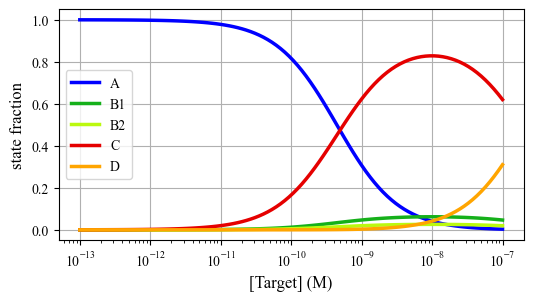

max at [T] =  9.933992677987828e-09
max of  0.8283393694145333


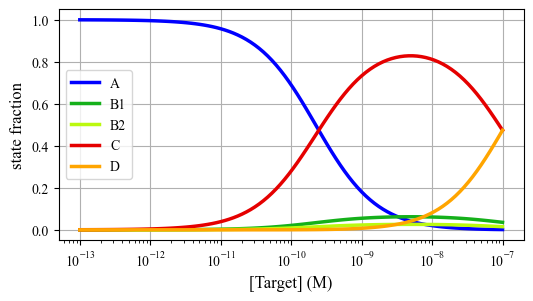

max at [T] =  4.966996338993914e-09
max of  0.8283393694145333


In [4]:
_ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, model="simple")
_ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, model="homodimer")

In [46]:
## PDGF-BB Aptamer Parameters and Simulations ##

In [9]:
kon_1 = 1.6e6 # 1/(M*s)
kon_2 = 1.6e6# 1/(M*s)
koff_1 = 1.24e-3 #1/s
koff_2 = 1.24e-3 #1/s
C_eff = 1e-9 # M

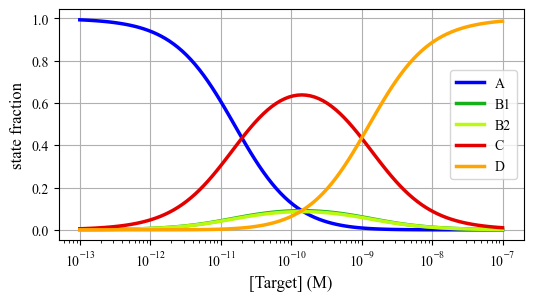

max at [T] =  1.4166666666666667e-10
max of  0.6382978723404255


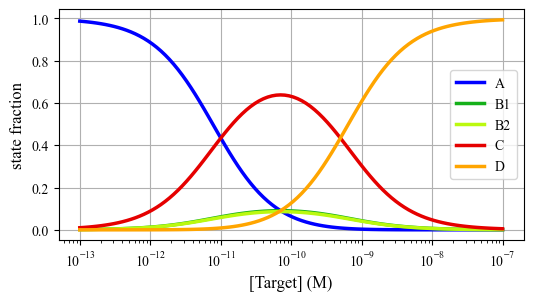

max at [T] =  7.083333333333333e-11
max of  0.6382978723404255


In [10]:
# _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=200e-12, plot_range=(-12, -8))
# _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=1e-9)

scale = 1
# _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, model="simple")
# _ = calculate_equilibrium_native(kon1=scale*kon_1, kon2=scale*kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, model="homodimer")
#
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=C_eff, model="simple")
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=C_eff, model="homodimer")





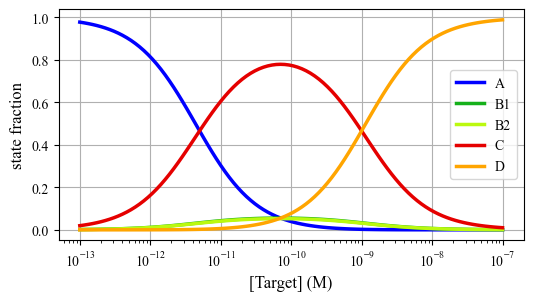

max at [T] =  7.083333333333333e-11
max of  0.7792207792207791


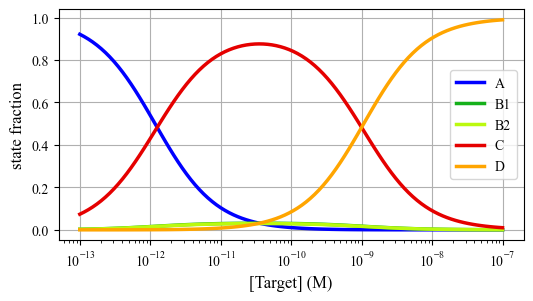

max at [T] =  3.541666666666667e-11
max of  0.8759124087591241


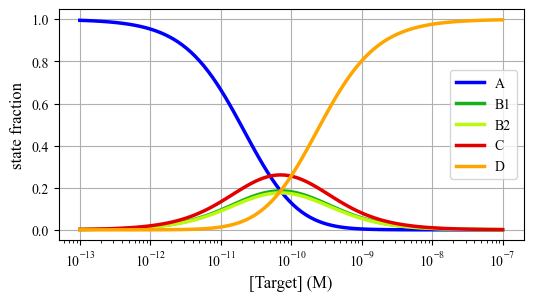

max at [T] =  7.083333333333333e-11
max of  0.2608695652173913


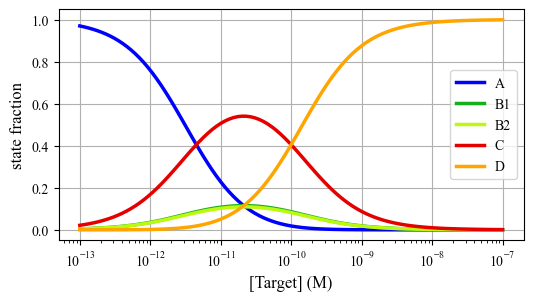

max at [T] =  2.1249999999999998e-11
max of  0.5405405405405406


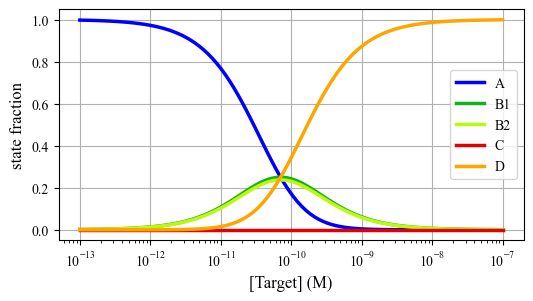

max at [T] =  7.083333333333333e-11
max of  0.0


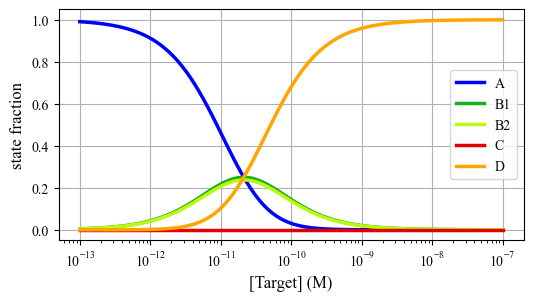

max at [T] =  2.1249999999999998e-11
max of  0.0


In [36]:
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=2e-9, model="homodimer")
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=0.5*1.7e-3, koff2=0.5*1.7e-3, Ceff=2e-9, model="homodimer")

_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=0.2e-9, model="homodimer")
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=0.3*1.7e-3, koff2=0.3*1.7e-3, Ceff=0.2e-9, model="homodimer")

_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=0, model="homodimer")
_ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=0.3*1.7e-3, koff2=0.3*1.7e-3, Ceff=0, model="homodimer")

3.2e-11


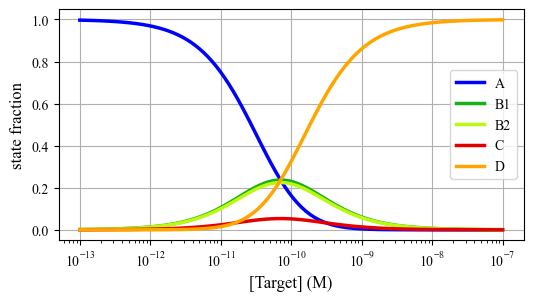

max at [T] =  7.083333333333333e-11
max of  0.053452115812917596
1e-10


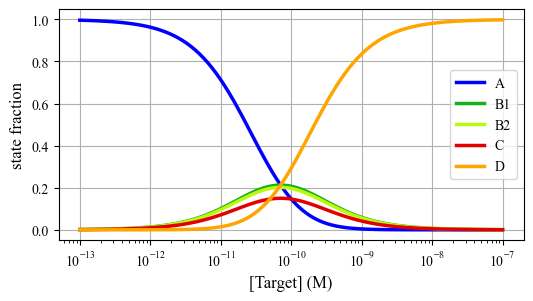

max at [T] =  7.083333333333333e-11
max of  0.15000000000000002
3.2e-10


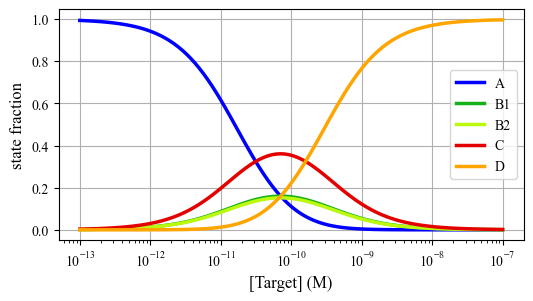

max at [T] =  7.083333333333333e-11
max of  0.3609022556390977
1e-09


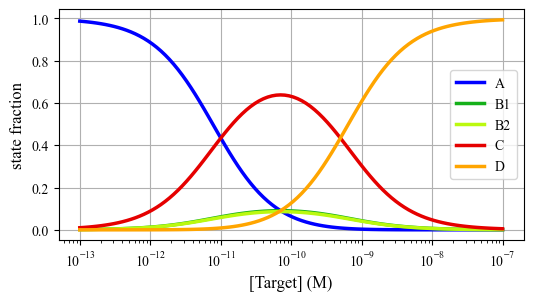

max at [T] =  7.083333333333333e-11
max of  0.6382978723404255
3.2e-09


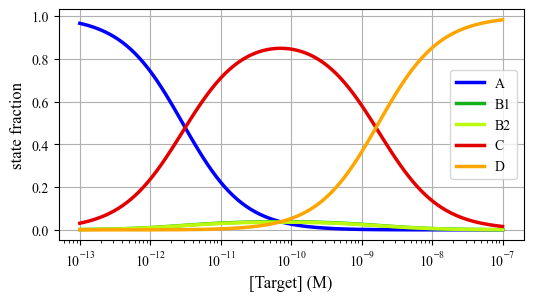

max at [T] =  7.083333333333333e-11
max of  0.8495575221238939
1e-08


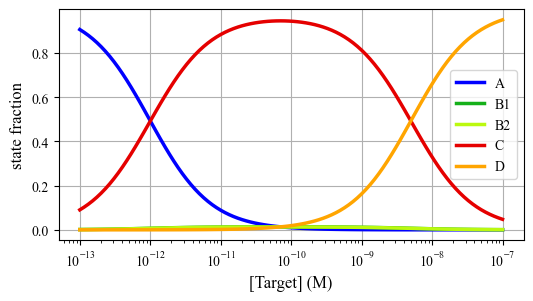

max at [T] =  7.083333333333333e-11
max of  0.9463722397476342


In [22]:
for Ceff in [32e-12, 100e-12, 320e-12, 1e-9, 3.2e-9, 10e-9]:
    print(Ceff)
    # _ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=Ceff, model="simple")
    _ = calculate_equilibrium_native(kon1=1.2e7, kon2=1.2e7, koff1=1.7e-3, koff2=1.7e-3, Ceff=Ceff, model="homodimer")

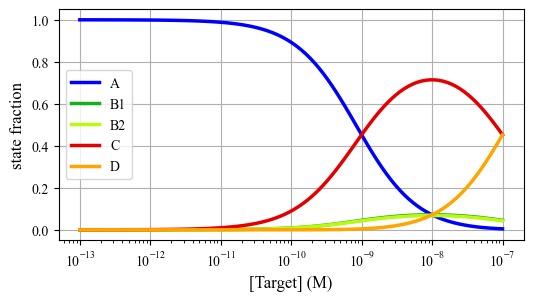

Kd effective:  1.270166537925831e-09
EC_50:  6.274606680622811e-10
max at [T] =  1e-08
max of  0.7142857142857143


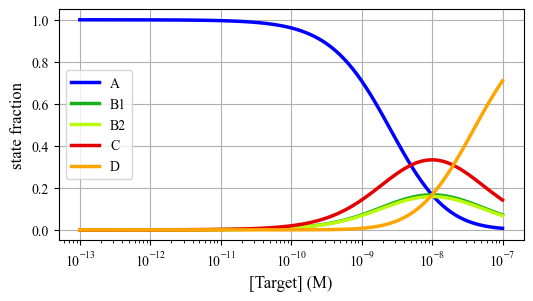

Kd effective:  nan
EC_50:  1.2701665379258333e-09
max at [T] =  1e-08
max of  0.3333333333333333


/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_63043/2869242557.py:75: RuntimeWarning: invalid value encountered in sqrt
  Kdeff = 1/ ((-b + np.sqrt((b*b) - 4*a*c)) / (2*a)) #not totally sure why inverting here but it works... note two roots from hook effect


In [53]:
## DNA NS modelling
kon_1 = 1e6  # 1/(M*s)
kon_2 = 1e6  # 1/(M*s)
koff_1 = 1e-4  #1/s
koff_2 = 1e-4  #1/s
alpha = 0.01
C_eff = 100e-9  # M
_ = calculate_equilibrium_native(kon1=alpha*kon_1, kon2=alpha*kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff)
_ = calculate_equilibrium_native(kon1=alpha*kon_1, kon2=alpha*kon_2, koff1=koff_1, koff2=koff_2, Ceff=20e-9)

# calculate_equilibrium_alpha(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, alpha=1)
# calculate_equilibrium_alpha(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, alpha=alpha)

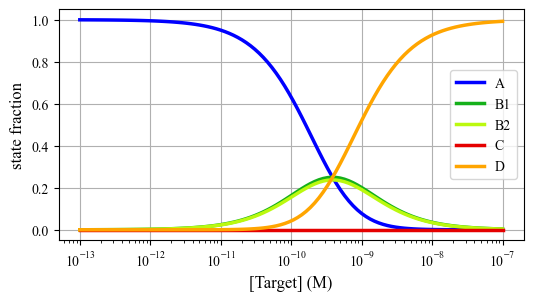

Kd effective:  -7.750000000000001e-10
EC_50:  1.3296897832170246e-10
max at [T] =  7.75e-10
max of  0.0


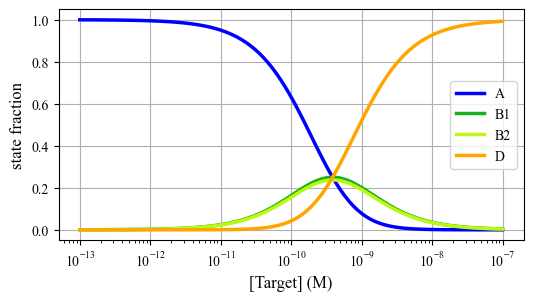

In [20]:
_ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=0*C_eff, model="homodimer")
_ = calculate_equilibrium_forced(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, model="homodimer")



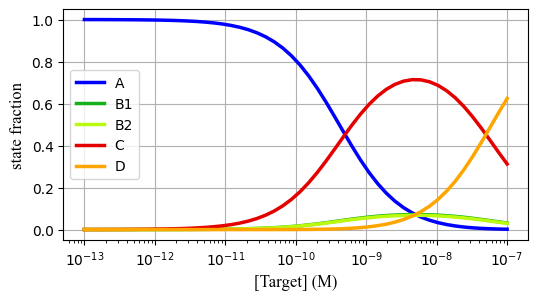

Kd effective:  6.350832689629155e-10
EC_50:  3.1373033403114057e-10
max at [T] =  5e-09
max of  0.7142857142857143


In [19]:
_ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=0.5*C_eff)


In [37]:
# Plots for fraction bound vs Kd and fraction bound vs Ceff

# define different Kds
kon_1 = 1.2e7 #1.6e6 # 1/(M*s)
koff_1 = 1.74e-3 #1.24e-3 #1/s

factor = np.sqrt(np.sqrt(10))
kon_2 = factor*kon_1 # 1/(M*s)
koff_2 = koff_1/factor #1/s

kon_3 = factor*kon_2# 1/(M*s)
koff_3 = koff_2/factor #1/s

C_eff1 = 1e-9 # M
C_eff2 = 3.2e-9
C_eff3 = 10e-9

Kd1 = koff_1/kon_1
Kd2 = koff_2/kon_2
Kd3 = koff_3/kon_3

print("Kd1: ", Kd1)
print("Kd2: ", Kd2)
print("Kd3: ", Kd3)

Kd1:  1.45e-10
Kd2:  4.58530260724415e-11
Kd3:  1.45e-11


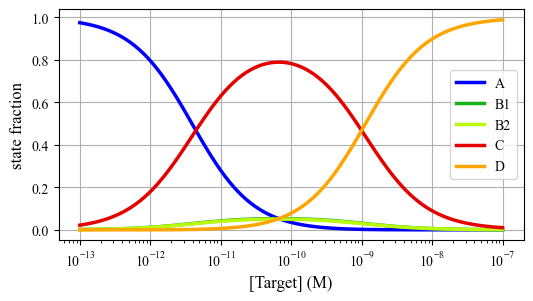

Kd effective:  5.1589140444956985e-12
EC_50:  3.1818346544376364e-12
max at [T] =  6.666666666666667e-11
max of  0.7894736842105264


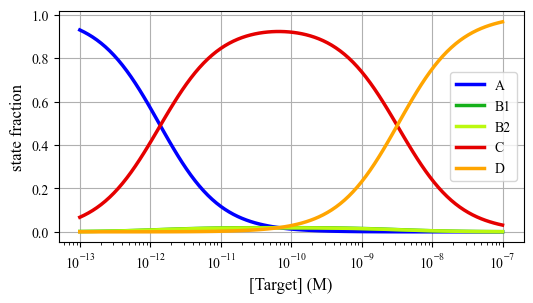

Kd effective:  1.4499609231923577e-12
EC_50:  1.2349915690612264e-12
max at [T] =  6.666666666666667e-11
max of  0.9230769230769231


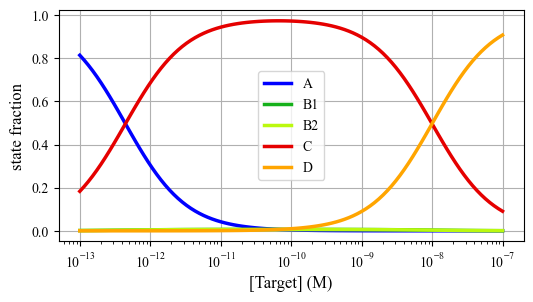

Kd effective:  4.5047101708598103e-13
EC_50:  4.2736798921516554e-13
max at [T] =  6.666666666666667e-11
max of  0.9740259740259741


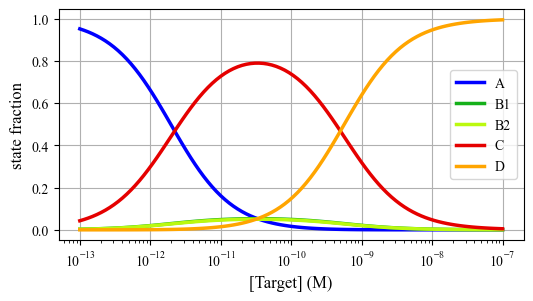

Kd effective:  5.1589140444956985e-12
EC_50:  3.1818346544376364e-12
max at [T] =  6.666666666666667e-11
max of  0.7894736842105264


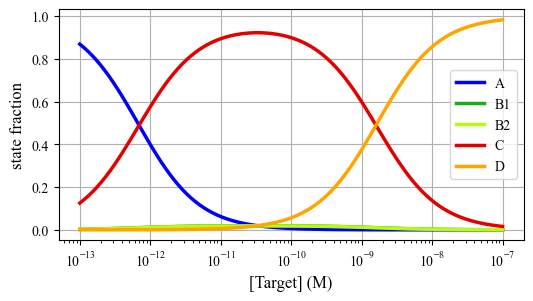

Kd effective:  1.4499609231923577e-12
EC_50:  1.2349915690612264e-12
max at [T] =  6.666666666666667e-11
max of  0.9230769230769231


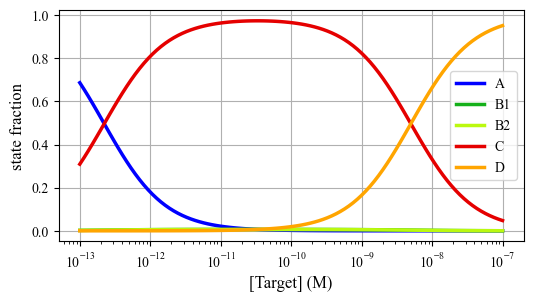

Kd effective:  4.5047101708598103e-13
EC_50:  4.2736798921516554e-13
max at [T] =  6.666666666666667e-11
max of  0.9740259740259741


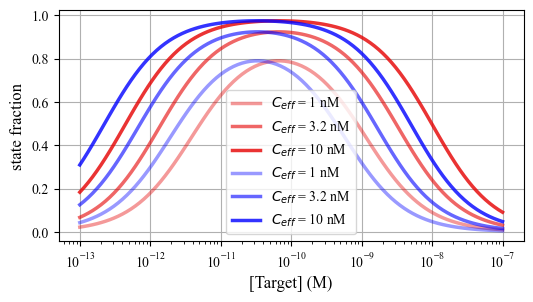

In [36]:
# Vary Ceff
model = "simple"
targets_1, _, _, _, Cfrac_1, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff1, model=model)
targets_2, _, _, _, Cfrac_2, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff2, model=model)
targets_3, _, _, _, Cfrac_3, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff3, model=model)

model = "homodimer"
targets_4, _, _, _, Cfrac_4, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff1, model=model)
targets_5, _, _, _, Cfrac_5, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff2, model=model)
targets_6, _, _, _, Cfrac_6, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff3, model=model)

plt.figure(figsize=(6, 3))
plt.semilogx(targets_1, Cfrac_1, label='$C_{eff}$ = 1 nM', linewidth=2.5, color='#E50000', alpha=0.4)
plt.semilogx(targets_2, Cfrac_2, label='$C_{eff}$ = 3.2 nM', linewidth=2.5, color='#E50000', alpha=0.6)
plt.semilogx(targets_3, Cfrac_3, label='$C_{eff}$ = 10 nM', linewidth=2.5, color='#E50000', alpha=0.8)

plt.semilogx(targets_4, Cfrac_4, label='$C_{eff}$ = 1 nM', linewidth=2.5, color='#0000FF', alpha=0.4)
plt.semilogx(targets_5, Cfrac_5, label='$C_{eff}$ = 3.2 nM', linewidth=2.5, color='#0000FF', alpha=0.6)
plt.semilogx(targets_6, Cfrac_6, label='$C_{eff}$ = 10 nM', linewidth=2.5, color='#0000FF', alpha=0.8)
#plt.title('nanoswitch equilibrium (no magnet)', fontname="Times New Roman", fontsize=14, fontweight='normal')
plt.xlabel('[Target] (M)', fontname="Times New Roman", fontsize=12, fontweight='normal')
plt.ylabel('state fraction', color='black', fontname="Times New Roman", fontsize=12, fontweight='normal')
plt.legend()
plt.grid()

plt.show()

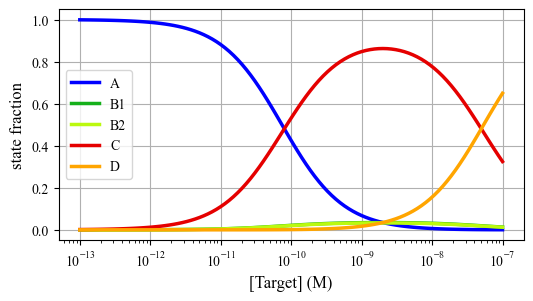

max at [T] =  2e-09
max of  0.8620689655172413


ValueError: not enough values to unpack (expected 9, got 8)

In [32]:
#Vary Kd
targets_1, _, _, _, Cfrac_1, _, _, _, _ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff)
targets_2, _, _, _, Cfrac_2, _, _, _, _ = calculate_equilibrium_native(kon1=3.2*kon_1, kon2=3.2*kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff)
targets_3, _, _, _, Cfrac_3, _, _, _, _ = calculate_equilibrium_native(kon1=10*kon_1, kon2=10*kon_1, koff1=koff_1, koff2=koff_1, Ceff=C_eff)

plt.figure(figsize=(6, 3))
plt.semilogx(targets_1, Cfrac_1, label=f'$K_d$ = 5 nM', linewidth=2.5, color='#E50000', alpha=0.4)
plt.semilogx(targets_2, Cfrac_2, label=f'$K_d$ = 1 nM', linewidth=2.5, color='#E50000', alpha=0.6)
plt.semilogx(targets_3, Cfrac_3, label=f'$K_d$ = 500 pM', linewidth=2.5, color='#E50000', alpha=0.8)
#plt.title('nanoswitch equilibrium (no magnet)', fontname="Times New Roman", fontsize=14, fontweight='normal')
plt.xlabel('[Target] (M)', fontname="Times New Roman", fontsize=12, fontweight='normal')
plt.ylabel('state fraction', color='black', fontname="Times New Roman", fontsize=12, fontweight='normal')
plt.legend()
plt.grid()

plt.show()

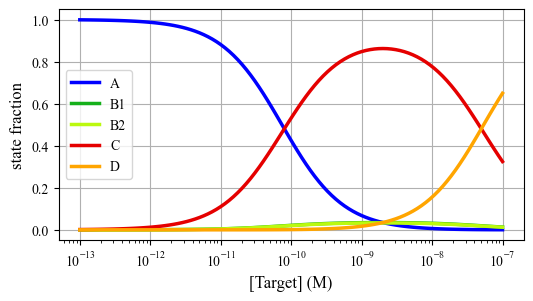

max at [T] =  2e-09
max of  0.8620689655172413


In [30]:
kon_1 = 5e5 # 1/(M*s)
kon_2 = 5e5# 1/(M*s)
koff_1 = 1e-3 #1/s
koff_2 = 1e-3 #1/s
C_eff = 50e-9 # M

_ = calculate_equilibrium_native(kon1=kon_1, kon2=kon_2, koff1=koff_1, koff2=koff_2, Ceff=C_eff, model="simple")
